# Inteligencia Artificial con Aplicaciones en Economía I

- Profesora: Lina María Castro
- Universidad Externado de Colombia, Facultad de Economía
- Integrantes: Daniel Peña, Santiago González y Sebastián Mendoza

# Etapa 3. Asociación y modelado predictivo de la deserción alta

## Importar librerías

In [1]:
import os
os.environ['PYTHONWARNINGS'] = 'ignore'
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (classification_report, confusion_matrix, roc_curve, auc, roc_auc_score,
                             precision_recall_curve, f1_score, recall_score, precision_score, accuracy_score)
from sklearn.inspection import permutation_importance
import shap

## Mejorar visualización de dataframes y gráficos

In [2]:
pd.options.display.max_columns = None
pd.options.display.float_format = '{:,.3f}'.format
sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

SEMILLA = 42
np.random.seed(SEMILLA)
AZUL, ROJO, GRIS = "#2a6f97", "#d1495b", "#8d99ae"

## Establecer la ruta y cargar la base municipal

In [3]:
ARCHIVO_CLAVE = os.path.join('data', 'processed', 'base_municipal.csv')
try:
    from google.colab import drive
    drive.mount('/content/drive')
    hallados = glob.glob(os.path.join('/content/drive/MyDrive', '**', ARCHIVO_CLAVE), recursive=True)
    os.chdir(hallados[0].replace(os.sep + ARCHIVO_CLAVE, ''))
except ImportError:
    if not os.path.exists(ARCHIVO_CLAVE) and os.path.exists(os.path.join('..', ARCHIVO_CLAVE)):
        os.chdir('..')
print("Carpeta de trabajo:", os.getcwd())

base = pd.read_csv(ARCHIVO_CLAVE, dtype={'cod_mpio': str, 'cod_depto': str})
print("Base municipal:", base.shape)
print(base['desercion_alta'].value_counts(normalize=True))

Carpeta de trabajo: /home/claude/out/proyecto_desercion_coca
Base municipal: (1121, 88)
desercion_alta
0   0.750
1   0.250
Name: proportion, dtype: float64


## Conjuntos de variables (definidos en el inventario de la etapa 2)

In [4]:
privaciones = [c for c in base.columns if c.startswith('priv_')]

COCA = ['coca_presencia', 'log_ha_coca', 'anios_coca', 'anios_coca_largo']
COCA_CAT = ['dinamica_coca']
CONTROLES = ['log_victimas_x1000', 'pct_rural', 'log_poblacion', 'pdet', 'ipm_cabecera'] + privaciones
EDUCACION = ['reprobacion_lag', 'repitencia_lag', 'cob_neta_media_lag']
HISTORIAL = ['desercion_lag']
DEPTO = ['departamento']

print("Faltantes en las variables del modelo:",
      base[COCA + COCA_CAT + CONTROLES + EDUCACION + HISTORIAL + DEPTO].isnull().sum().sum())

Faltantes en las variables del modelo: 0


# Parte A. Asociación: ¿la coca se relaciona con la deserción una vez se controla?

In [5]:
def matriz(variables, con_depto):
    X = base[variables].astype(float)
    if con_depto:
        X = pd.concat([X, pd.get_dummies(base['departamento'], prefix='depto', drop_first=True, dtype=float)], axis=1)
    return sm.add_constant(X)

modelo_prueba = sm.OLS(base['desercion_prom'], matriz(['coca_presencia'] + CONTROLES + EDUCACION, True)).fit()
bp = het_breuschpagan(modelo_prueba.resid, modelo_prueba.model.exog)
jb = jarque_bera(modelo_prueba.resid)
reset = linear_reset(modelo_prueba, power=2, test_type='fitted', use_f=True)
print(f"Breusch-Pagan (H0: homocedasticidad): LM = {bp[0]:.1f}, p-valor = {bp[1]:.4f}")
print(f"Jarque-Bera (H0: residuos normales): JB = {jb[0]:.1f}, p-valor = {jb[1]:.4f}")
print(f"Ramsey RESET (H0: forma funcional correcta): F = {reset.fvalue:.2f}, p-valor = {reset.pvalue:.4f}")

Breusch-Pagan (H0: homocedasticidad): LM = 216.0, p-valor = 0.0000
Jarque-Bera (H0: residuos normales): JB = 106.7, p-valor = 0.0000
Ramsey RESET (H0: forma funcional correcta): F = 1.02, p-valor = 0.3116


In [6]:
especificaciones = {
    '(1) Solo coca': ([], False),
    '(2) + conflicto, pobreza, ruralidad, tamaño, PDET': (CONTROLES, False),
    '(3) + departamento': (CONTROLES, True),
    '(4) + educación rezagada': (CONTROLES + EDUCACION, True),
    '(5) + deserción 2019-2021': (CONTROLES + EDUCACION + HISTORIAL, True),
}

filas = []
for medida in COCA:
    for nombre, (controles, con_depto) in especificaciones.items():
        modelo = sm.OLS(base['desercion_prom'], matriz([medida] + controles, con_depto)).fit(cov_type='HC1')
        filas.append({'medida de coca': medida, 'especificación': nombre, 'coeficiente': modelo.params[medida],
                      'error estándar': modelo.bse[medida], 'p-valor': modelo.pvalues[medida], 'R2': modelo.rsquared})
asociacion = pd.DataFrame(filas)
pd.pivot_table(asociacion, index='especificación', columns='medida de coca', values=['coeficiente', 'p-valor'], sort=False)

coeficiente              \
medida de coca                                    coca_presencia log_ha_coca   
especificación                                                                 
(1) Solo coca                                              0.859       0.152   
(2) + conflicto, pobreza, ruralidad, tamaño, PDET          0.007      -0.019   
(3) + departamento                                         0.382       0.077   
(4) + educación rezagada                                   0.378       0.071   
(5) + deserción 2019-2021                                  0.290       0.061   

                                                                               \
medida de coca                                    anios_coca anios_coca_largo   
especificación                                                                  
(1) Solo coca                                          0.104            0.055   
(2) + conflicto, pobreza, ruralidad, tamaño, PDET      0.011            0.014   
(3) + departamento                                     0.043            0.027   
(4) + educación rezagada                               0.042            0.026   
(5) + deserción 2019-2021                              0.038            0.022   

                                                         p-valor              \
medida de coca                                    coca_presencia log_ha_coca   
especificación                                                                 
(1) Solo coca                                              0.000       0.000   
(2) + conflicto, pobreza, ruralidad, tamaño, PDET          0.966       0.564   
(3) + departamento                                         0.018       0.011   
(4) + educación rezagada                                   0.022       0.019   
(5) + deserción 2019-2021                                  0.040       0.015   

                                                                               
medida de coca                                    anios_coca anios_coca_largo  
especificación                                                                 
(1) Solo coca                                          0.000            0.000  
(2) + conflicto, pobreza, ruralidad, tamaño, PDET      0.557            0.118  
(3) + departamento                                     0.016            0.001  
(4) + educación rezagada                               0.020            0.002  
(5) + deserción 2019-2021                              0.014            0.002

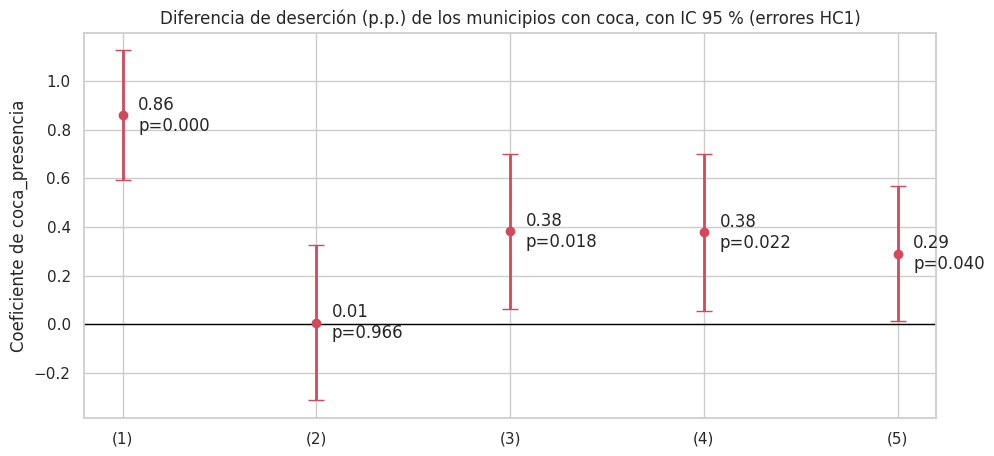

['(1) Solo coca', '(2) + conflicto, pobreza, ruralidad, tamaño, PDET', '(3) + departamento', '(4) + educación rezagada', '(5) + deserción 2019-2021']


In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
pres = asociacion[asociacion['medida de coca'] == 'coca_presencia'].reset_index(drop=True)
ax.errorbar(pres.index, pres['coeficiente'], yerr=1.96 * pres['error estándar'], fmt='o', color=ROJO, capsize=6, lw=2)
ax.axhline(0, color='black', lw=1)
ax.set_xticks(pres.index)
ax.set_xticklabels([e.split(') ')[0] + ')' for e in pres['especificación']])
for i, r in pres.iterrows():
    ax.text(i + 0.08, r['coeficiente'], f"{r['coeficiente']:.2f}\np={r['p-valor']:.3f}", va='center')
ax.set(title='Diferencia de deserción (p.p.) de los municipios con coca, con IC 95 % (errores HC1)',
       ylabel='Coeficiente de coca_presencia')
plt.savefig('outputs/figures/fig14_asociacion_coca_ols.png', dpi=160, bbox_inches='tight')
plt.show()
print(list(especificaciones.keys()))

In [8]:
lpm_bruto = sm.OLS(base['desercion_alta'], matriz(['coca_presencia'], False)).fit(cov_type='HC1')
lpm_ajustado = sm.OLS(base['desercion_alta'], matriz(['coca_presencia'] + CONTROLES + EDUCACION, True)).fit(cov_type='HC1')
lpm_dinamica = sm.OLS(base['desercion_alta'], pd.concat([matriz(CONTROLES + EDUCACION, True),
                      pd.get_dummies(base['dinamica_coca'], dtype=float).drop(columns='Sin coca')], axis=1)).fit(cov_type='HC1')
pd.DataFrame({
    'Modelo': ['Bruto (2.ª entrega: 40,7 % vs 21,8 %)', 'Ajustado: controles + departamento + educación',
               'Ajustado, dinámica: Salió', 'Ajustado, dinámica: Entró', 'Ajustado, dinámica: Persistente'],
    'Cambio en la probabilidad de deserción alta (p.p.)': [100 * lpm_bruto.params['coca_presencia'], 100 * lpm_ajustado.params['coca_presencia'],
                                                           100 * lpm_dinamica.params['Salió'], 100 * lpm_dinamica.params['Entró'], 100 * lpm_dinamica.params['Persistente']],
    'p-valor': [lpm_bruto.pvalues['coca_presencia'], lpm_ajustado.pvalues['coca_presencia'],
                lpm_dinamica.pvalues['Salió'], lpm_dinamica.pvalues['Entró'], lpm_dinamica.pvalues['Persistente']]})

,Modelo,Cambio en la probabilidad de deserción alta (p.p.),p-valor
0,"Bruto (2.ª entrega: 40,7 % vs 21,8 %)",18.960,0.000
1,Ajustado: controles + departamento + educación,8.139,0.112
2,"Ajustado, dinámica: Salió",-2.821,0.654
3,"Ajustado, dinámica: Entró",40.947,0.009
4,"Ajustado, dinámica: Persistente",5.860,0.269


### Colinealidad entre las medidas de coca (VIF)

In [9]:
def calcular_vif(X_df):
    vif = pd.DataFrame({'variable': X_df.columns,
                        'VIF': [variance_inflation_factor(X_df.values, i) for i in range(X_df.shape[1])]})
    return vif.sort_values('VIF', ascending=False)

X_vif = sm.add_constant(base[COCA + ['log_victimas_x1000', 'pct_rural', 'log_poblacion', 'pdet']].astype(float))
calcular_vif(X_vif).query("variable != 'const'")

,variable,VIF
3,anios_coca,24.551
1,coca_presencia,12.778
4,anios_coca_largo,9.441
2,log_ha_coca,7.583
5,log_victimas_x1000,2.098
8,pdet,2.047
7,log_poblacion,1.532
6,pct_rural,1.530


In [10]:
print("Correlación de Pearson log_ha_coca vs anios_coca:", round(base[['log_ha_coca', 'anios_coca']].corr().iloc[0, 1], 2))
print("Correlación de Pearson coca_presencia vs log_ha_coca:", round(base[['coca_presencia', 'log_ha_coca']].corr().iloc[0, 1], 2))

Correlación de Pearson log_ha_coca vs anios_coca: 0.92
Correlación de Pearson coca_presencia vs log_ha_coca: 0.91


# Parte B. Predicción de la deserción alta

## 1. División de los datos (antes de cualquier preprocesamiento)

In [11]:
y = base['desercion_alta']
X = base[COCA + COCA_CAT + CONTROLES + EDUCACION + HISTORIAL + DEPTO + ['ipm']]

es_train = base['conjunto'] == 'train'
X_train, X_test, y_train, y_test = X[es_train], X[~es_train], y[es_train], y[~es_train]
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Proporción de deserción alta en train: {y_train.mean():.3f} | en test: {y_test.mean():.3f}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

Train: (896, 31) | Test: (225, 31)
Proporción de deserción alta en train: 0.250 | en test: 0.249


## 2. Preprocesamiento dentro de un Pipeline

In [12]:
def crear_pipeline(numericas, categoricas, modelo, pca_privaciones=False):
    transformadores = []
    if pca_privaciones:
        otras = [v for v in numericas if v not in privaciones]
        transformadores.append(('num', StandardScaler(), otras))
        transformadores.append(('pca_priv', Pipeline([('scaler', StandardScaler()), ('pca', PCA(n_components=4, random_state=SEMILLA))]), privaciones))
    else:
        transformadores.append(('num', StandardScaler(), numericas))
    if categoricas:
        transformadores.append(('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categoricas))
    preprocesador = ColumnTransformer(transformers=transformadores, remainder='drop')
    return Pipeline(steps=[('preprocessor', preprocesador), ('model', modelo)])

conteo = y_train.value_counts()
scale_pos_weight = conteo[0] / conteo[1]
print(f"scale_pos_weight para XGBoost: {scale_pos_weight:.2f}")

scale_pos_weight para XGBoost: 3.00


## 3. Decisiones de modelado pendientes (validación cruzada solo en train)

In [13]:
def evaluar_cv(numericas, categoricas, modelo, nombre, pca_privaciones=False):
    pipe = crear_pipeline(numericas, categoricas, modelo, pca_privaciones)
    columnas = numericas + categoricas
    pr = cross_val_score(pipe, X_train[columnas], y_train, cv=cv, scoring='average_precision', n_jobs=-1)
    roc = cross_val_score(pipe, X_train[columnas], y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    return {'especificación': nombre, 'PR-AUC (CV)': pr.mean(), 'DE PR-AUC': pr.std(), 'ROC-AUC (CV)': roc.mean(), 'pr_pliegues': pr}

logit = LogisticRegression(C=0.1, class_weight='balanced', max_iter=5000, random_state=SEMILLA)

### 3.1 Logit: ¿log de hectáreas, años con coca o ambas? (correlación 0,91)

In [14]:
base_logit = CONTROLES + EDUCACION
opciones = {'solo presencia': ['coca_presencia'], 'presencia + log_ha_coca': ['coca_presencia', 'log_ha_coca'],
            'presencia + anios_coca': ['coca_presencia', 'anios_coca'], 'presencia + log_ha + anios': ['coca_presencia', 'log_ha_coca', 'anios_coca'],
            'las 4 medidas': COCA}
tabla_coca_logit = pd.DataFrame([evaluar_cv(base_logit + v, DEPTO, logit, k) for k, v in opciones.items()]).drop(columns='pr_pliegues')
tabla_coca_logit

,especificación,PR-AUC (CV),DE PR-AUC,ROC-AUC (CV)
0,solo presencia,0.598,0.076,0.830
1,presencia + log_ha_coca,0.598,0.074,0.832
2,presencia + anios_coca,0.596,0.076,0.829
3,presencia + log_ha + anios,0.599,0.074,0.831
4,las 4 medidas,0.599,0.079,0.832


In [15]:
COCA_LOGIT = ['coca_presencia', 'log_ha_coca']
print("Medidas de coca para el Logit:", COCA_LOGIT)

Medidas de coca para el Logit: ['coca_presencia', 'log_ha_coca']


### 3.2 ¿Incluir el departamento? (explica el 44,9 % de la variación)

In [16]:
tabla_depto = pd.DataFrame([
    evaluar_cv(base_logit + COCA_LOGIT, [], logit, 'Logit sin departamento'),
    evaluar_cv(base_logit + COCA_LOGIT, DEPTO, logit, 'Logit con departamento'),
    evaluar_cv(base_logit + COCA_LOGIT + HISTORIAL, [], logit, 'Logit + historial, sin departamento'),
    evaluar_cv(base_logit + COCA_LOGIT + HISTORIAL, DEPTO, logit, 'Logit + historial, con departamento'),
]).drop(columns='pr_pliegues')
tabla_depto

,especificación,PR-AUC (CV),DE PR-AUC,ROC-AUC (CV)
0,Logit sin departamento,0.522,0.087,0.784
1,Logit con departamento,0.598,0.074,0.832
2,"Logit + historial, sin departamento",0.683,0.063,0.872
3,"Logit + historial, con departamento",0.713,0.053,0.886


### 3.3 ¿PCA sobre las privaciones o las 15 privaciones por separado?

In [17]:
tabla_pca = pd.DataFrame([
    evaluar_cv(base_logit + COCA_LOGIT, DEPTO, logit, '15 privaciones'),
    evaluar_cv(base_logit + COCA_LOGIT, DEPTO, logit, '4 componentes principales (PCA dentro del pipeline)', pca_privaciones=True),
]).drop(columns='pr_pliegues')
tabla_pca

,especificación,PR-AUC (CV),DE PR-AUC,ROC-AUC (CV)
0,15 privaciones,0.598,0.074,0.832
1,4 componentes principales (PCA dentro del pipe...,0.556,0.063,0.819


### 3.4 Verificación de variables descartadas en la etapa 2

In [18]:
DESCARTADAS = ['tamano_grupo_2017', 'sedes_internet_2017', 'ipm_rural', 'pct_pob_5_16', 'etc_certificada', 'cambio_coca',
               'log_ha_max_2001_2020', 'cob_neta_lag', 'cob_bruta_lag', 'cob_neta_secundaria_lag', 'cob_bruta_media_lag',
               'cob_neta_primaria_lag', 'cob_neta_transicion_lag', 'tasa_matriculacion_5_16_lag', 'repitencia_secundaria_lag',
               'repitencia_primaria_lag', 'reprobacion_secundaria_lag', 'reprobacion_primaria_lag']
completos = base.dropna(subset=['tamano_grupo_2017', 'sedes_internet_2017']).index
Xc_train = base.loc[base.index.isin(X_train.index) & base.index.isin(completos)]
yc_train = Xc_train['desercion_alta']
filas = []
for nombre, extra in [('seleccionadas', []), ('+ tamano_grupo_2017', ['tamano_grupo_2017']),
                      ('+ todas las descartadas sin fuga ni historial', DESCARTADAS)]:
    columnas = base_logit + COCA + extra
    pipe = crear_pipeline(columnas, DEPTO, RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced', random_state=SEMILLA, n_jobs=-1))
    pr = cross_val_score(pipe, Xc_train[columnas + DEPTO], yc_train, cv=cv, scoring='average_precision', n_jobs=-1)
    filas.append({'conjunto (Random Forest)': 'Escenario A: ' + nombre, 'variables': len(columnas) + 1, 'PR-AUC (CV)': pr.mean(), 'DE': pr.std()})

for nombre, extra in [('seleccionadas + desercion_lag', HISTORIAL),
                      ('+ deserción rezagada por nivel', HISTORIAL + ['desercion_transicion_lag', 'desercion_primaria_lag', 'desercion_secundaria_lag', 'desercion_media_lag'])]:
    columnas = base_logit + COCA + extra
    pipe = crear_pipeline(columnas, DEPTO, RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced', random_state=SEMILLA, n_jobs=-1))
    pr = cross_val_score(pipe, Xc_train[columnas + DEPTO], yc_train, cv=cv, scoring='average_precision', n_jobs=-1)
    filas.append({'conjunto (Random Forest)': 'Escenario B: ' + nombre, 'variables': len(columnas) + 1, 'PR-AUC (CV)': pr.mean(), 'DE': pr.std()})
print("Municipios de train con tamaño de grupo y sedes 2017:", len(Xc_train), "de", len(X_train))
pd.DataFrame(filas)

Municipios de train con tamaño de grupo y sedes 2017: 886 de 896


,conjunto (Random Forest),variables,PR-AUC (CV),DE
0,Escenario A: seleccionadas,28,0.658,0.054
1,Escenario A: + tamano_grupo_2017,29,0.650,0.060
2,Escenario A: + todas las descartadas sin fuga ...,46,0.654,0.034
3,Escenario B: seleccionadas + desercion_lag,29,0.734,0.029
4,Escenario B: + deserción rezagada por nivel,33,0.726,0.035


## 4. Búsqueda de hiperparámetros: dos escenarios, cinco modelos

In [19]:
def variables_modelo(nombre_modelo, escenario, con_coca=True):
    if nombre_modelo in ['Regresión Logística', 'KNN']:
        numericas = CONTROLES + EDUCACION + (COCA_LOGIT if con_coca else [])
        categoricas = DEPTO
    else:
        numericas = CONTROLES + EDUCACION + ['ipm'] + (COCA if con_coca else [])
        categoricas = DEPTO + (COCA_CAT if con_coca else [])
    if escenario == 'B':
        numericas = numericas + HISTORIAL
    return numericas, categoricas

modelos = {
    'Regresión Logística': (LogisticRegression(class_weight='balanced', max_iter=5000, random_state=SEMILLA),
                            {'model__C': [0.01, 0.1, 1, 10, 100, 1000]}),
    'KNN': (KNeighborsClassifier(),
            {'model__n_neighbors': [5, 11, 21, 31, 51], 'model__weights': ['uniform', 'distance']}),
    'Árbol de Decisión': (DecisionTreeClassifier(class_weight='balanced', random_state=SEMILLA),
                          {'model__max_depth': [3, 5, 7, 10], 'model__min_samples_leaf': [10, 20, 50]}),
    'Random Forest': (RandomForestClassifier(class_weight='balanced', random_state=SEMILLA, n_jobs=-1),
                      {'model__n_estimators': [200, 400], 'model__max_depth': [5, 10, None], 'model__min_samples_leaf': [1, 5]}),
    'XGBoost': (XGBClassifier(objective='binary:logistic', eval_metric='logloss', scale_pos_weight=scale_pos_weight,
                              random_state=SEMILLA, n_jobs=-1),
                {'model__n_estimators': [100, 200], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [3, 5]}),
}

busquedas = {}
for escenario in ['A', 'B']:
    for nombre, (modelo, grilla) in modelos.items():
        numericas, categoricas = variables_modelo(nombre, escenario)
        grid = GridSearchCV(crear_pipeline(numericas, categoricas, modelo), param_grid=grilla, cv=cv,
                            scoring={'pr_auc': 'average_precision', 'roc_auc': 'roc_auc'}, refit='pr_auc', n_jobs=-1)
        grid.fit(X_train[numericas + categoricas], y_train)
        busquedas[(escenario, nombre)] = grid
        print(f"Escenario {escenario} | {nombre:20s} | PR-AUC CV = {grid.best_score_:.3f} | {grid.best_params_}")

Escenario A | Regresión Logística  | PR-AUC CV = 0.720 | {'model__C': 1000}


Escenario A | KNN                  | PR-AUC CV = 0.596 | {'model__n_neighbors': 5, 'model__weights': 'distance'}


Escenario A | Árbol de Decisión    | PR-AUC CV = 0.479 | {'model__max_depth': 7, 'model__min_samples_leaf': 50}


Escenario A | Random Forest        | PR-AUC CV = 0.670 | {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 400}


Escenario A | XGBoost              | PR-AUC CV = 0.660 | {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}


Escenario B | Regresión Logística  | PR-AUC CV = 0.756 | {'model__C': 1000}


Escenario B | KNN                  | PR-AUC CV = 0.671 | {'model__n_neighbors': 31, 'model__weights': 'distance'}


Escenario B | Árbol de Decisión    | PR-AUC CV = 0.605 | {'model__max_depth': 5, 'model__min_samples_leaf': 50}


Escenario B | Random Forest        | PR-AUC CV = 0.730 | {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 400}


Escenario B | XGBoost              | PR-AUC CV = 0.705 | {'model__learning_rate': 0.05, 'model__max_depth': 5, 'model__n_estimators': 200}


In [20]:
resultados_cv = pd.DataFrame([{
    'escenario': e, 'modelo': m, 'PR-AUC (CV)': g.best_score_,
    'DE PR-AUC': g.cv_results_['std_test_pr_auc'][g.best_index_],
    'ROC-AUC (CV)': g.cv_results_['mean_test_roc_auc'][g.best_index_],
    'mejores hiperparámetros': g.best_params_} for (e, m), g in busquedas.items()])
resultados_cv.sort_values(['escenario', 'PR-AUC (CV)'], ascending=[True, False])

,escenario,modelo,PR-AUC (CV),DE PR-AUC,ROC-AUC (CV),mejores hiperparámetros
0,A,Regresión Logística,0.720,0.032,0.867,{'model__C': 1000}
3,A,Random Forest,0.670,0.067,0.850,"{'model__max_depth': 10, 'model__min_samples_l..."
4,A,XGBoost,0.660,0.058,0.838,"{'model__learning_rate': 0.1, 'model__max_dept..."
1,A,KNN,0.596,0.091,0.809,"{'model__n_neighbors': 5, 'model__weights': 'd..."
2,A,Árbol de Decisión,0.479,0.025,0.760,"{'model__max_depth': 7, 'model__min_samples_le..."
5,B,Regresión Logística,0.756,0.035,0.884,{'model__C': 1000}
8,B,Random Forest,0.730,0.032,0.887,"{'model__max_depth': None, 'model__min_samples..."
9,B,XGBoost,0.705,0.029,0.878,"{'model__learning_rate': 0.05, 'model__max_dep..."
6,B,KNN,0.671,0.088,0.853,"{'model__n_neighbors': 31, 'model__weights': '..."
7,B,Árbol de Decisión,0.605,0.042,0.845,"{'model__max_depth': 5, 'model__min_samples_le..."


### 4.1 ¿Hay sobreajuste? Entrenamiento vs. validación cruzada vs. prueba

In [21]:
filas = []
for (escenario, nombre), grid in busquedas.items():
    numericas, categoricas = variables_modelo(nombre, escenario)
    columnas = numericas + categoricas
    fila = {'escenario': escenario, 'modelo': nombre}
    for etiqueta, Xs, ys in [('train', X_train, y_train), ('test', X_test, y_test)]:
        prob = grid.best_estimator_.predict_proba(Xs[columnas])[:, 1]
        precision_c, recall_c, _ = precision_recall_curve(ys, prob)
        fila[f'PR-AUC {etiqueta}'] = auc(recall_c, precision_c)
    fila['PR-AUC CV'] = grid.best_score_
    fila['brecha train - CV'] = fila['PR-AUC train'] - fila['PR-AUC CV']
    filas.append(fila)
sobreajuste = pd.DataFrame(filas)[['escenario', 'modelo', 'PR-AUC train', 'PR-AUC CV', 'PR-AUC test', 'brecha train - CV']]
sobreajuste

,escenario,modelo,PR-AUC train,PR-AUC CV,PR-AUC test,brecha train - CV
0,A,Regresión Logística,0.782,0.720,0.577,0.062
1,A,KNN,1.000,0.596,0.587,0.404
2,A,Árbol de Decisión,0.641,0.479,0.454,0.162
3,A,Random Forest,0.998,0.670,0.674,0.328
4,A,XGBoost,0.990,0.660,0.649,0.330
5,B,Regresión Logística,0.828,0.756,0.667,0.072
6,B,KNN,1.000,0.671,0.675,0.329
7,B,Árbol de Decisión,0.722,0.605,0.657,0.117
8,B,Random Forest,1.000,0.730,0.729,0.270
9,B,XGBoost,1.000,0.705,0.698,0.295


### 4.2 ¿El ranking depende de cómo se arman los pliegues?

In [22]:
filas = []
for (escenario, nombre), grid in busquedas.items():
    numericas, categoricas = variables_modelo(nombre, escenario)
    columnas = numericas + categoricas
    puntajes = []
    for semilla_pliegues in range(5):
        cv_r = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla_pliegues)
        puntajes.extend(cross_val_score(grid.best_estimator_, X_train[columnas], y_train, cv=cv_r, scoring='average_precision', n_jobs=-1))
    puntajes = np.array(puntajes)
    filas.append({'escenario': escenario, 'modelo': nombre, 'PR-AUC promedio (25 pliegues)': puntajes.mean(),
                  'DE': puntajes.std(), 'mínimo': puntajes.min(), 'máximo': puntajes.max()})
estabilidad = pd.DataFrame(filas).sort_values(['escenario', 'PR-AUC promedio (25 pliegues)'], ascending=[True, False])
estabilidad

,escenario,modelo,PR-AUC promedio (25 pliegues),DE,mínimo,máximo
0,A,Regresión Logística,0.707,0.055,0.551,0.808
3,A,Random Forest,0.668,0.040,0.614,0.747
4,A,XGBoost,0.651,0.057,0.545,0.782
1,A,KNN,0.617,0.055,0.509,0.726
2,A,Árbol de Decisión,0.482,0.043,0.405,0.584
5,B,Regresión Logística,0.749,0.051,0.617,0.833
8,B,Random Forest,0.726,0.032,0.674,0.781
9,B,XGBoost,0.703,0.033,0.631,0.769
6,B,KNN,0.679,0.044,0.586,0.770
7,B,Árbol de Decisión,0.586,0.038,0.508,0.654


### 4.3 Cómo decide el mejor árbol (primeros niveles)

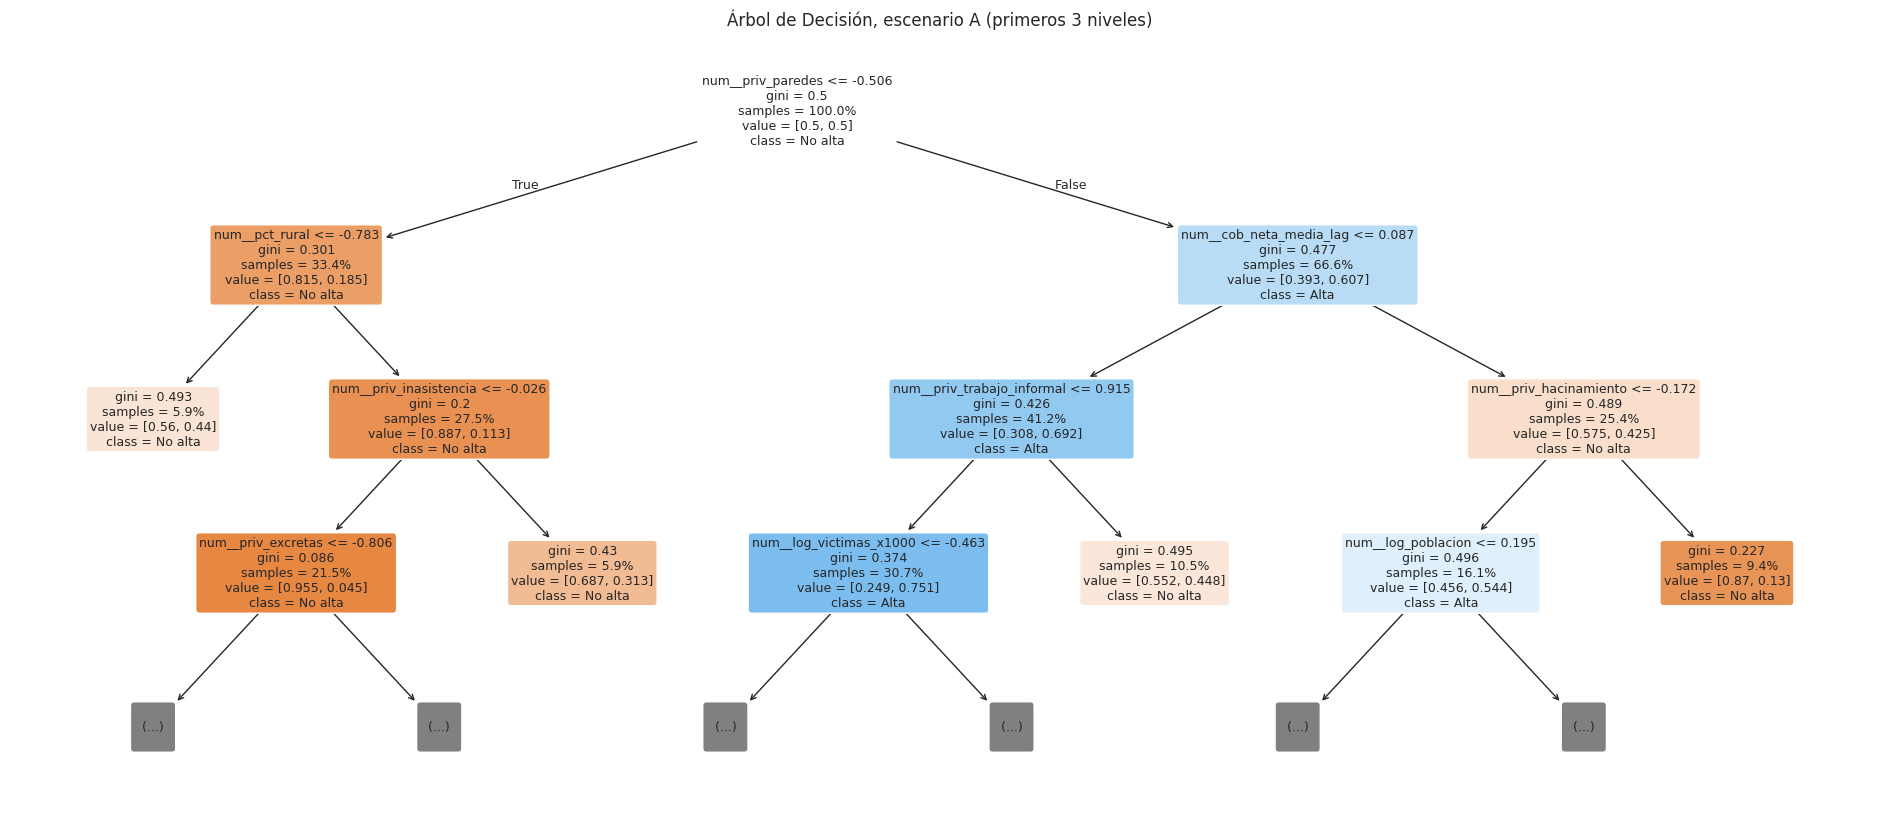

In [23]:
arbol = busquedas[('A', 'Árbol de Decisión')].best_estimator_
plt.figure(figsize=(24, 10))
plot_tree(arbol.named_steps['model'], max_depth=3, feature_names=arbol.named_steps['preprocessor'].get_feature_names_out(),
          class_names=['No alta', 'Alta'], filled=True, rounded=True, fontsize=9, proportion=True)
plt.title('Árbol de Decisión, escenario A (primeros 3 niveles)')
plt.savefig('outputs/figures/fig20_arbol_decision.png', dpi=130, bbox_inches='tight')
plt.show()

## 5. Aporte marginal de la coca

In [24]:
filas = []
for (escenario, nombre), grid in busquedas.items():
    modelo_opt = grid.best_estimator_.named_steps['model']
    fila = {'escenario': escenario, 'modelo': nombre}
    for etiqueta, con_coca in [('base', False), ('base + coca', True)]:
        numericas, categoricas = variables_modelo(nombre, escenario, con_coca)
        pipe = crear_pipeline(numericas, categoricas, modelo_opt)
        fila[f'PR-AUC {etiqueta}'] = cross_val_score(pipe, X_train[numericas + categoricas], y_train, cv=cv, scoring='average_precision', n_jobs=-1)
        fila[f'ROC-AUC {etiqueta}'] = cross_val_score(pipe, X_train[numericas + categoricas], y_train, cv=cv, scoring='roc_auc', n_jobs=-1).mean()
    diferencia = fila['PR-AUC base + coca'] - fila['PR-AUC base']
    fila.update({'Δ PR-AUC': diferencia.mean(), 'DE de Δ': diferencia.std(), 'pliegues donde la coca mejora': f"{(diferencia > 0).sum()} de 5",
                 'Δ ROC-AUC': fila['ROC-AUC base + coca'] - fila['ROC-AUC base']})
    fila['PR-AUC base'], fila['PR-AUC base + coca'] = fila['PR-AUC base'].mean(), fila['PR-AUC base + coca'].mean()
    filas.append(fila)
aporte_coca = pd.DataFrame(filas)
aporte_coca

,escenario,modelo,PR-AUC base,ROC-AUC base,PR-AUC base + coca,ROC-AUC base + coca,Δ PR-AUC,DE de Δ,pliegues donde la coca mejora,Δ ROC-AUC
0,A,Regresión Logística,0.714,0.862,0.720,0.867,0.005,0.009,2 de 5,0.005
1,A,KNN,0.597,0.811,0.596,0.809,-0.001,0.032,3 de 5,-0.002
2,A,Árbol de Decisión,0.479,0.760,0.479,0.760,-0.000,0.000,1 de 5,-0.000
3,A,Random Forest,0.667,0.843,0.670,0.850,0.003,0.028,4 de 5,0.007
4,A,XGBoost,0.659,0.837,0.660,0.838,0.001,0.019,3 de 5,0.001
5,B,Regresión Logística,0.757,0.880,0.756,0.884,-0.001,0.008,2 de 5,0.004
6,B,KNN,0.671,0.853,0.671,0.853,0.000,0.019,2 de 5,0.000
7,B,Árbol de Decisión,0.605,0.845,0.605,0.845,-0.000,0.003,1 de 5,-0.000
8,B,Random Forest,0.729,0.886,0.730,0.887,0.001,0.023,3 de 5,0.001
9,B,XGBoost,0.702,0.880,0.705,0.878,0.003,0.017,3 de 5,-0.002


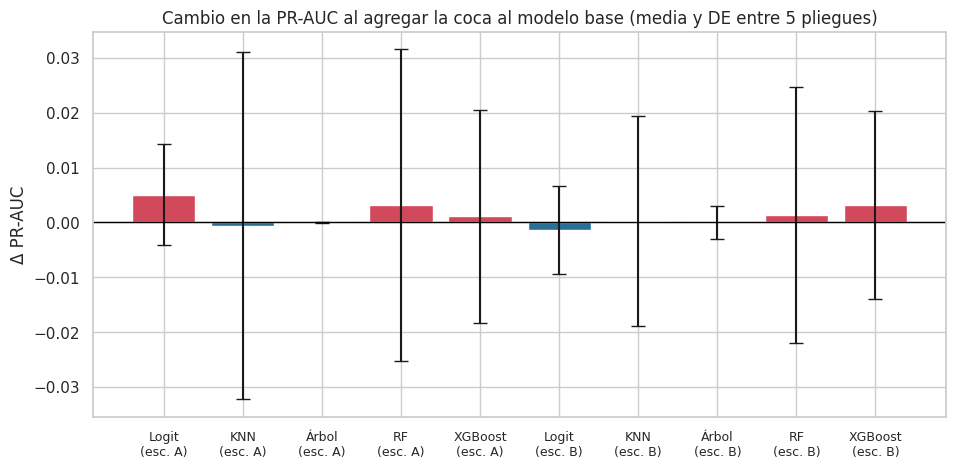

In [25]:
fig, ax = plt.subplots(figsize=(11, 5))
etiquetas = [f"{r['modelo']}\n(esc. {r['escenario']})" for _, r in aporte_coca.iterrows()]
etiquetas = [e.replace('Regresión Logística', 'Logit').replace('Árbol de Decisión', 'Árbol').replace('Random Forest', 'RF') for e in etiquetas]
ax.bar(etiquetas, aporte_coca['Δ PR-AUC'], yerr=aporte_coca['DE de Δ'], color=[ROJO if v > 0 else AZUL for v in aporte_coca['Δ PR-AUC']], capsize=5)
ax.axhline(0, color='black', lw=1)
ax.set(title='Cambio en la PR-AUC al agregar la coca al modelo base (media y DE entre 5 pliegues)', ylabel='Δ PR-AUC')
plt.xticks(rotation=0, fontsize=9)
plt.savefig('outputs/figures/fig15_aporte_marginal_coca.png', dpi=160, bbox_inches='tight')
plt.show()

## 6. Selección del modelo campeón y evaluación final en el test

In [26]:
campeones = {}
for escenario in ['A', 'B']:
    sub = estabilidad[estabilidad['escenario'] == escenario].sort_values('PR-AUC promedio (25 pliegues)', ascending=False)
    campeones[escenario] = sub.iloc[0]['modelo']
    print(f"Campeón escenario {escenario}: {campeones[escenario]} (PR-AUC promedio = {sub.iloc[0]['PR-AUC promedio (25 pliegues)']:.3f})")

Campeón escenario A: Regresión Logística (PR-AUC promedio = 0.707)
Campeón escenario B: Regresión Logística (PR-AUC promedio = 0.749)


### 6.1 Umbral de clasificación

In [27]:
def umbral_por_recall(pipe, columnas, objetivo_recall=0.80):
    prob_oof = cross_val_predict(pipe, X_train[columnas], y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    fpr, tpr, umbrales = roc_curve(y_train, prob_oof)
    indice = np.argmax(tpr >= objetivo_recall)
    return umbrales[indice]

def metricas_test(y_real, prob, umbral):
    pred = (prob >= umbral).astype(int)
    precision_c, recall_c, _ = precision_recall_curve(y_real, prob)
    return {'PR-AUC': auc(recall_c, precision_c), 'ROC-AUC': roc_auc_score(y_real, prob), 'umbral': umbral,
            'recall': recall_score(y_real, pred), 'precisión': precision_score(y_real, pred), 'F1': f1_score(y_real, pred),
            'accuracy': accuracy_score(y_real, pred)}

filas, probabilidades = [], {}
for (escenario, nombre), grid in busquedas.items():
    numericas, categoricas = variables_modelo(nombre, escenario)
    columnas = numericas + categoricas
    prob = grid.best_estimator_.predict_proba(X_test[columnas])[:, 1]
    probabilidades[(escenario, nombre)] = prob
    umbral = umbral_por_recall(grid.best_estimator_, columnas)
    for tipo, u in [('0,5', 0.5), ('recall ≥ 0,80 (elegido en train)', umbral)]:
        filas.append({'escenario': escenario, 'modelo': nombre, 'umbral usado': tipo, **metricas_test(y_test, prob, u)})
resultados_test = pd.DataFrame(filas)
resultados_test

,escenario,modelo,umbral usado,PR-AUC,ROC-AUC,umbral,recall,precisión,F1,accuracy
0,A,Regresión Logística,"0,5",0.577,0.811,0.500,0.696,0.506,0.586,0.756
1,A,Regresión Logística,"recall ≥ 0,80 (elegido en train)",0.577,0.811,0.422,0.750,0.494,0.596,0.747
2,A,KNN,"0,5",0.587,0.813,0.500,0.464,0.650,0.542,0.804
3,A,KNN,"recall ≥ 0,80 (elegido en train)",0.587,0.813,0.202,0.786,0.444,0.568,0.702
4,A,Árbol de Decisión,"0,5",0.454,0.728,0.500,0.607,0.507,0.553,0.756
5,A,Árbol de Decisión,"recall ≥ 0,80 (elegido en train)",0.454,0.728,0.411,0.732,0.376,0.497,0.631
6,A,Random Forest,"0,5",0.674,0.859,0.500,0.482,0.711,0.574,0.822
7,A,Random Forest,"recall ≥ 0,80 (elegido en train)",0.674,0.859,0.310,0.804,0.536,0.643,0.778
8,A,XGBoost,"0,5",0.649,0.841,0.500,0.661,0.587,0.622,0.800
9,A,XGBoost,"recall ≥ 0,80 (elegido en train)",0.649,0.841,0.259,0.821,0.474,0.601,0.729


### 6.2 Reporte de clasificación y matriz de confusión de los campeones

--- Escenario A: Regresión Logística (umbral = 0.422) ---
                    precision    recall  f1-score   support

       No alta (0)       0.90      0.75      0.82       169
Deserción alta (1)       0.49      0.75      0.60        56

          accuracy                           0.75       225
         macro avg       0.70      0.75      0.71       225
      weighted avg       0.80      0.75      0.76       225

--- Escenario B: Regresión Logística (umbral = 0.478) ---
                    precision    recall  f1-score   support

       No alta (0)       0.91      0.83      0.87       169
Deserción alta (1)       0.60      0.75      0.67        56

          accuracy                           0.81       225
         macro avg       0.75      0.79      0.77       225
      weighted avg       0.83      0.81      0.82       225



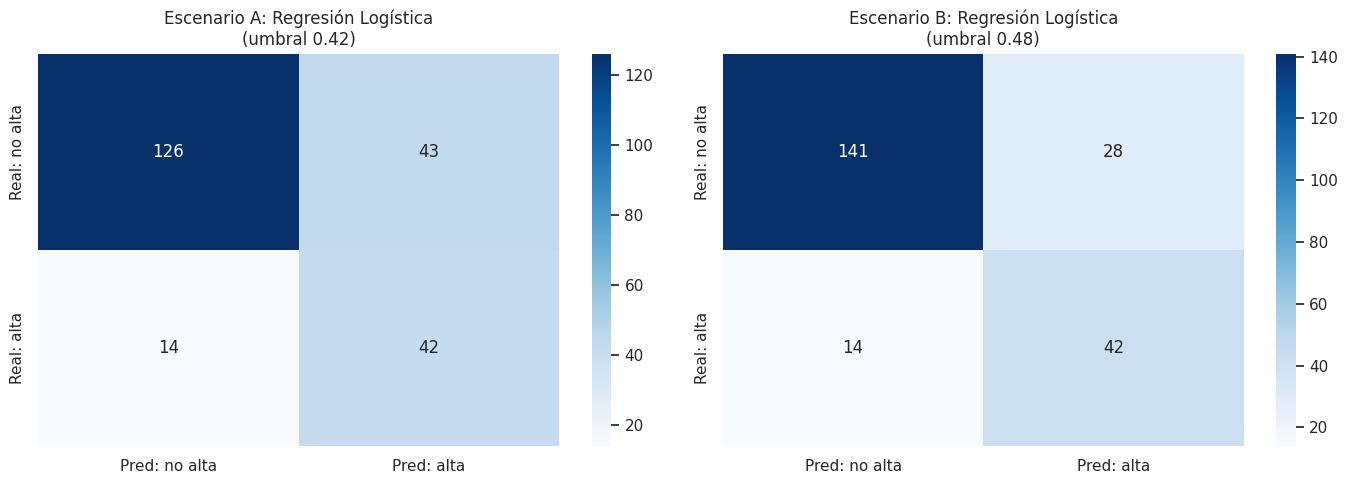

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, escenario in zip(axes, ['A', 'B']):
    nombre = campeones[escenario]
    numericas, categoricas = variables_modelo(nombre, escenario)
    umbral = resultados_test.query("escenario == @escenario and modelo == @nombre and `umbral usado` != '0,5'")['umbral'].iloc[0]
    pred = (probabilidades[(escenario, nombre)] >= umbral).astype(int)
    print(f"--- Escenario {escenario}: {nombre} (umbral = {umbral:.3f}) ---")
    print(classification_report(y_test, pred, target_names=['No alta (0)', 'Deserción alta (1)']))
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Pred: no alta', 'Pred: alta'], yticklabels=['Real: no alta', 'Real: alta'])
    ax.set_title(f'Escenario {escenario}: {nombre}\n(umbral {umbral:.2f})')
plt.tight_layout()
plt.savefig('outputs/figures/fig16_matrices_confusion.png', dpi=160, bbox_inches='tight')
plt.show()

### 6.3 Curvas ROC y precisión-recall en el test

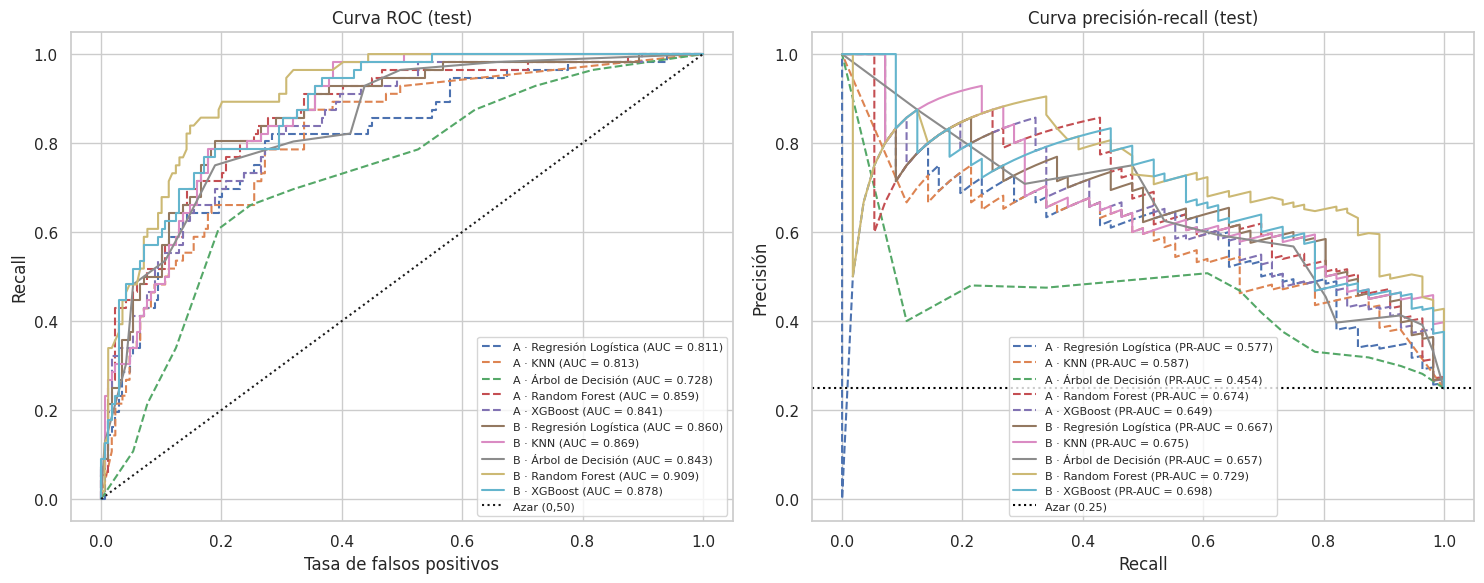

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for (escenario, nombre), prob in probabilidades.items():
    estilo = '-' if escenario == 'B' else '--'
    fpr, tpr, _ = roc_curve(y_test, prob)
    precision_c, recall_c, _ = precision_recall_curve(y_test, prob)
    axes[0].plot(fpr, tpr, estilo, label=f"{escenario} · {nombre} (AUC = {auc(fpr, tpr):.3f})")
    axes[1].plot(recall_c, precision_c, estilo, label=f"{escenario} · {nombre} (PR-AUC = {auc(recall_c, precision_c):.3f})")
axes[0].plot([0, 1], [0, 1], 'k:', label='Azar (0,50)')
axes[0].set(title='Curva ROC (test)', xlabel='Tasa de falsos positivos', ylabel='Recall')
axes[1].axhline(y_test.mean(), color='black', ls=':', label=f'Azar ({y_test.mean():.2f})')
axes[1].set(title='Curva precisión-recall (test)', xlabel='Recall', ylabel='Precisión')
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('outputs/figures/fig17_curvas_roc_pr.png', dpi=160, bbox_inches='tight')
plt.show()

### 6.4 ¿Aporta la coca en el test?

In [30]:
filas = []
for escenario in ['A', 'B']:
    nombre = campeones[escenario]
    modelo_opt = busquedas[(escenario, nombre)].best_estimator_.named_steps['model']
    for etiqueta, con_coca in [('base', False), ('base + coca', True)]:
        numericas, categoricas = variables_modelo(nombre, escenario, con_coca)
        pipe = crear_pipeline(numericas, categoricas, modelo_opt).fit(X_train[numericas + categoricas], y_train)
        prob = pipe.predict_proba(X_test[numericas + categoricas])[:, 1]
        precision_c, recall_c, _ = precision_recall_curve(y_test, prob)
        filas.append({'escenario': escenario, 'modelo': nombre, 'variables': etiqueta,
                      'PR-AUC test': auc(recall_c, precision_c), 'ROC-AUC test': roc_auc_score(y_test, prob)})
pd.DataFrame(filas)

,escenario,modelo,variables,PR-AUC test,ROC-AUC test
0,A,Regresión Logística,base,0.589,0.816
1,A,Regresión Logística,base + coca,0.577,0.811
2,B,Regresión Logística,base,0.678,0.868
3,B,Regresión Logística,base + coca,0.667,0.860


## 7. Interpretación

### 7.1 Odds ratios de la Regresión Logística

In [31]:
for escenario in ['A', 'B']:
    grid = busquedas[(escenario, 'Regresión Logística')]
    nombres = grid.best_estimator_.named_steps['preprocessor'].get_feature_names_out()
    coef = pd.DataFrame({'variable': nombres, 'coeficiente': grid.best_estimator_.named_steps['model'].coef_[0]})
    coef['odds_ratio'] = np.exp(coef['coeficiente'])
    coef = coef[~coef['variable'].str.startswith('cat__departamento')].sort_values('coeficiente', ascending=False)
    print(f"--- Escenario {escenario} (variables numéricas estandarizadas: odds ratio por 1 desviación estándar) ---")
    display(coef.head(8))
    display(coef.tail(5))

--- Escenario A (variables numéricas estandarizadas: odds ratio por 1 desviación estándar) ---


,variable,coeficiente,odds_ratio
4,num__ipm_cabecera,1.283,3.607
23,num__coca_presencia,0.817,2.264
17,num__priv_aseguramiento,0.664,1.943
6,num__priv_bajo_logro,0.410,1.506
20,num__reprobacion_lag,0.280,1.323
14,num__priv_pisos,0.275,1.317
12,num__priv_inasistencia,0.204,1.227
3,num__pdet,0.198,1.219


,variable,coeficiente,odds_ratio
16,num__priv_agua,-0.565,0.568
22,num__cob_neta_media_lag,-0.589,0.555
24,num__log_ha_coca,-0.652,0.521
7,num__priv_primera_infancia,-0.767,0.465
9,num__priv_dependencia,-0.954,0.385


--- Escenario B (variables numéricas estandarizadas: odds ratio por 1 desviación estándar) ---


,variable,coeficiente,odds_ratio
25,num__desercion_lag,1.524,4.591
4,num__ipm_cabecera,1.144,3.139
23,num__coca_presencia,0.766,2.152
17,num__priv_aseguramiento,0.580,1.787
14,num__priv_pisos,0.295,1.343
20,num__reprobacion_lag,0.244,1.276
18,num__priv_trabajo_infantil,0.151,1.163
3,num__pdet,0.138,1.148


,variable,coeficiente,odds_ratio
22,num__cob_neta_media_lag,-0.381,0.683
16,num__priv_agua,-0.417,0.659
9,num__priv_dependencia,-0.539,0.583
24,num__log_ha_coca,-0.566,0.568
7,num__priv_primera_infancia,-0.600,0.549


### 7.2 Importancia por permutación (modelo campeón de cada escenario, en el test)

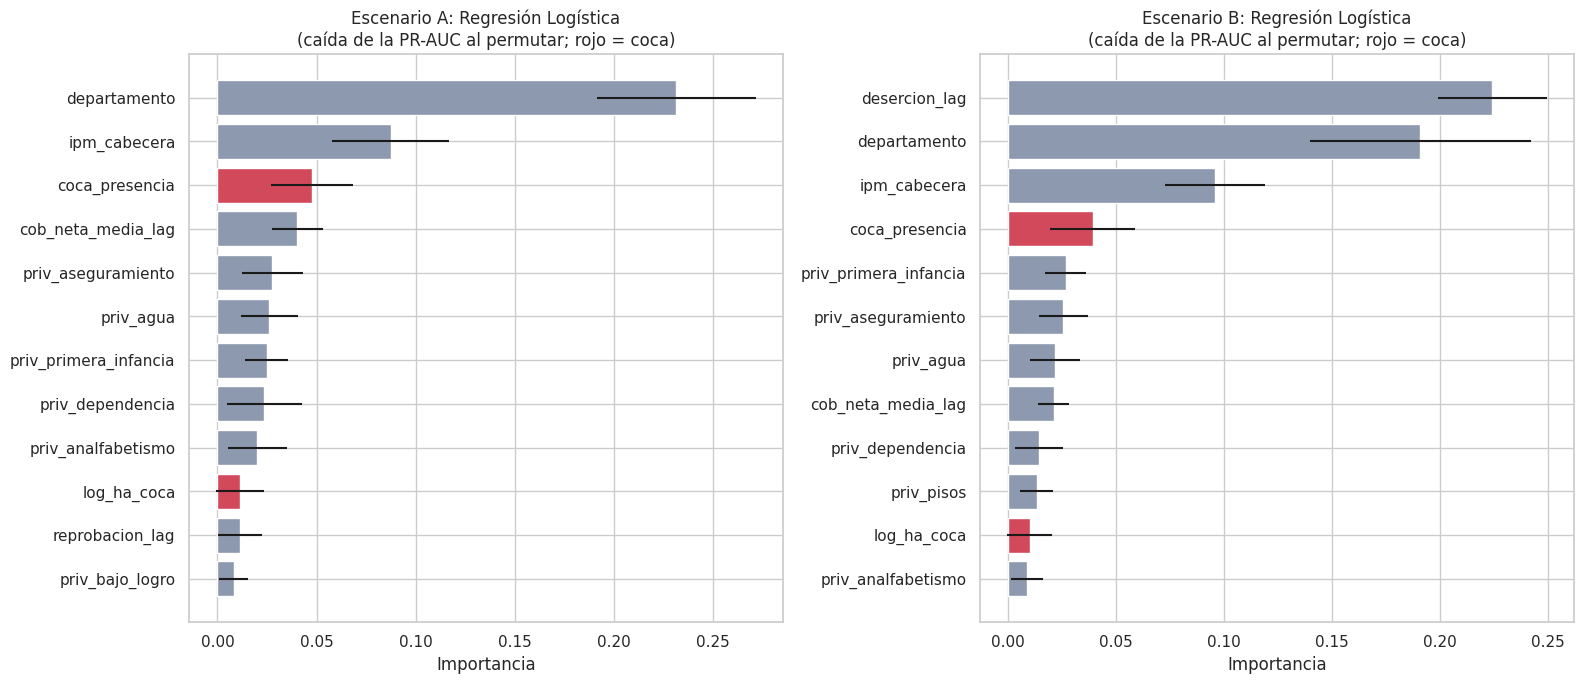

In [32]:
importancias = {}
for escenario in ['A', 'B']:
    nombre = campeones[escenario]
    numericas, categoricas = variables_modelo(nombre, escenario)
    resultado = permutation_importance(busquedas[(escenario, nombre)].best_estimator_, X_test[numericas + categoricas], y_test,
                                       scoring='average_precision', n_repeats=30, random_state=SEMILLA, n_jobs=-1)
    importancias[escenario] = pd.DataFrame({'variable': numericas + categoricas, 'importancia': resultado.importances_mean,
                                            'DE': resultado.importances_std}).sort_values('importancia', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, escenario in zip(axes, ['A', 'B']):
    top = importancias[escenario].head(12)
    ax.barh(top['variable'][::-1], top['importancia'][::-1], xerr=top['DE'][::-1],
            color=[ROJO if v in COCA + COCA_CAT else GRIS for v in top['variable'][::-1]])
    ax.set(title=f"Escenario {escenario}: {campeones[escenario]}\n(caída de la PR-AUC al permutar; rojo = coca)", xlabel='Importancia')
plt.tight_layout()
plt.savefig('outputs/figures/fig18_importancia_permutacion.png', dpi=160, bbox_inches='tight')
plt.show()

In [33]:
for escenario in ['A', 'B']:
    imp = importancias[escenario]
    print(f"Escenario {escenario}: posición de las variables de coca en el ranking de importancia")
    display(imp.reset_index(drop=True).reset_index().rename(columns={'index': 'posición'}).pipe(lambda d: d[d['variable'].isin(COCA + COCA_CAT)]))

Escenario A: posición de las variables de coca en el ranking de importancia


,posición,variable,importancia,DE
2,2,coca_presencia,0.048,0.021
9,9,log_ha_coca,0.011,0.012


Escenario B: posición de las variables de coca en el ranking de importancia


,posición,variable,importancia,DE
3,3,coca_presencia,0.039,0.020
10,10,log_ha_coca,0.010,0.011


### 7.3 SHAP: dirección del efecto (XGBoost, escenario A)

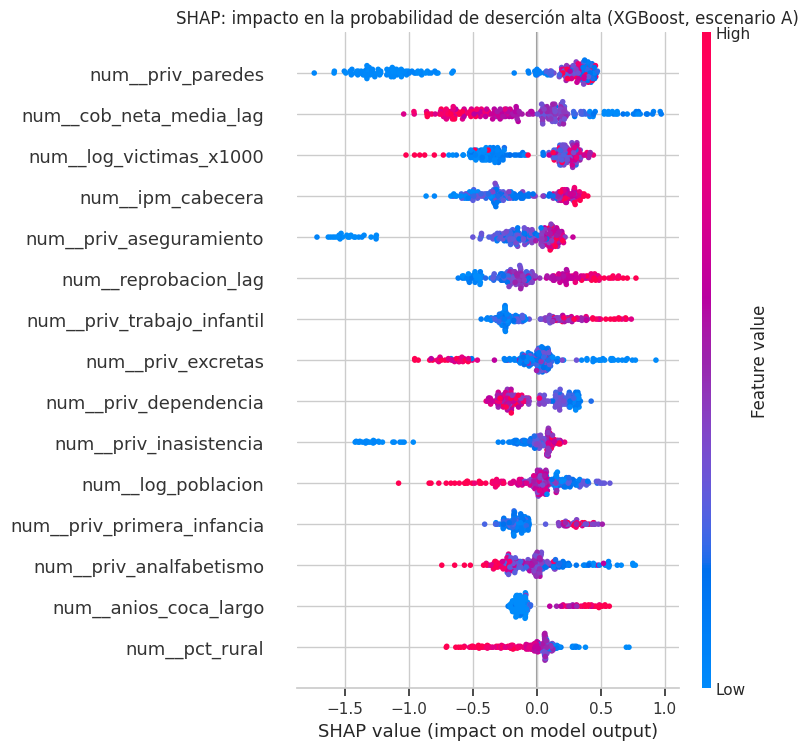

In [34]:
grid_xgb = busquedas[('A', 'XGBoost')]
numericas, categoricas = variables_modelo('XGBoost', 'A')
preprocesador = grid_xgb.best_estimator_.named_steps['preprocessor']
X_test_proc = pd.DataFrame(preprocesador.transform(X_test[numericas + categoricas]), columns=preprocesador.get_feature_names_out())
explainer = shap.TreeExplainer(grid_xgb.best_estimator_.named_steps['model'])
shap_values = explainer.shap_values(X_test_proc)
shap.summary_plot(shap_values, X_test_proc, max_display=15, show=False)
plt.title('SHAP: impacto en la probabilidad de deserción alta (XGBoost, escenario A)')
plt.savefig('outputs/figures/fig19_shap_xgboost.png', dpi=160, bbox_inches='tight')
plt.show()

## 8. Guardar resultados

In [35]:
asociacion.to_csv('outputs/reports/asociacion_ols_coca.csv', index=False, encoding='utf-8-sig')
resultados_cv.to_csv('outputs/reports/resultados_cv_modelos.csv', index=False, encoding='utf-8-sig')
estabilidad.to_csv('outputs/reports/estabilidad_cv_modelos.csv', index=False, encoding='utf-8-sig')
sobreajuste.to_csv('outputs/reports/sobreajuste_train_cv_test.csv', index=False, encoding='utf-8-sig')
aporte_coca.to_csv('outputs/reports/aporte_marginal_coca.csv', index=False, encoding='utf-8-sig')
resultados_test.to_csv('outputs/reports/resultados_test_modelos.csv', index=False, encoding='utf-8-sig')
pd.concat([imp.assign(escenario=e) for e, imp in importancias.items()]).to_csv('outputs/reports/importancia_permutacion.csv', index=False, encoding='utf-8-sig')
print("Resultados guardados en outputs/reports/")

Resultados guardados en outputs/reports/
